# COLMAP: From Photographs to a 3D Reconstruction

## Introduction

**SC5006 · Computer Vision & Application · Week 9**  
**Topics:** SIFT, descriptor matching, epipolar geometry, triangulation, structure from motion (SfM), and bundle adjustment.

A camera observes a 3D scene through 2D projections. In this lab you will reconstruct a static scene from overlapping photographs, inspect camera poses and a coloured sparse point cloud, and explain why a reconstruction can fail even when many image features are detected.

By the end, you should be able to:
1. distinguish a descriptor match from a geometrically verified correspondence;
2. implement the ratio test, Sampson error, and two-view triangulation;
3. interpret COLMAP's camera convention and reconstruction diagnostics;
4. conduct a controlled experiment and justify a capture strategy.

**Suggested schedule:** 15 min setup and baseline; 30 min matching and geometry; 30 min reconstruction analysis; 25 min comparison and discussion. Downloads may take extra time.

**Prerequisites:** Python, NumPy, matrix multiplication, homogeneous coordinates, and the pinhole camera model. No model training is required.



Run the complete supplied baseline first, then complete Q1–Q5. Tutorial 07 uses the same static fern scene as its companion tutorial. The question groups total 100 points.

### Evaluation metrics

Report registered views, sparse points, mean track length and mean reprojection error in pixels. Report the actual detected keypoints as well as the requested feature budget. These are internal fit and coverage diagnostics; the photographs have no supplied ground-truth poses or 3D points.

Pipeline time includes extraction, matching and mapping. A single run, including first-use initialization, does not establish a speed ranking. COLMAP's scene scale is arbitrary.

## Submission

Please submit:

- Your completed `tutorial07_colmap_STUDENT.ipynb`, with outputs visible
- `colmap_baseline_submission.zip`, containing the latest saved reconstructions, database, images and run records
- `tutorial07_question_results.zip`, containing your report, comparison table and figures

Keep every `###YOUR CODE HERE###` marker and question number. Complete all code and written answers. Total: **100 points**.

| Section | Points |
|---|---:|
| Q1 — Matching and robust geometry | 20 |
| Q2 — Projection and triangulation | 25 |
| Q3 — Reconstruction diagnostics | 25 |
| Q4 — Controlled feature-budget experiment | 20 |
| Q5 — Capture design and limitations | 10 |
| **Total** | **100** |

---

## Before starting — runnable tutorial

1. Upload this notebook to Google Colab. Under **Runtime → Change runtime type**, select **CPU (no hardware accelerator required)**. Use one fresh hosted runtime for this tutorial.
2. Run **Install in this runtime** once. If packages were installed, choose **Runtime → Restart session**, then continue at **Environment check**. The notebook runs in Colab's current runtime; no kernel registration or kernel selection is required.
3. Run the supplied baseline cells in order and **stop before Q1**. Do not use **Run all** on an unfinished student notebook: the exercise placeholders intentionally raise errors.
4. Complete the code and written answers, then run Q1–Q5 in order. Download the completed notebook and both result ZIPs before leaving the session.

The ZIP contains the example photographs; uploading the notebook alone also works because missing photographs are downloaded from the pinned public source. Model weights used by Tutorial 09 are downloaded at first use. A runtime reset may delete local files, so download the generated baseline ZIP before it happens.

After a kernel restart with results still present, run **Restore after a kernel restart**, then the completed questions. After a VM reset, extract your saved baseline ZIP into the new working folder and install dependencies before restoring. Local Jupyter users may run the same installation cell in their current environment, or install the included requirements file.


### Install in this runtime

This tutorial uses the public **`pycolmap==3.13.0` CPU wheel** for extraction, matching and mapping. It needs no CUDA COLMAP build, custom wheel or GPU. The two feature-budget configurations both run on CPU.

Run the following cell once. If it changes packages, restart the session and continue at **Environment check**, skipping the installation cell on that restart. Use a fresh runtime for each tutorial.

In [1]:
# Run this cell once in a fresh Colab runtime (or your current Jupyter environment).
import sys, subprocess, json
from importlib import metadata
if not (3, 10) <= sys.version_info[:2] <= (3, 12):
    raise RuntimeError('This pinned lesson environment requires Python 3.10–3.12; use a Colab Python 3.12 runtime.')
PACKAGES = ['pycolmap==3.13.0', 'numpy==1.26.4', 'matplotlib==3.10.3', 'Pillow==11.2.1', 'opencv-python==4.11.0.86']
def installed_version(name):
    try: return metadata.version(name).split('+')[0]
    except metadata.PackageNotFoundError: return None
needs_install = any(installed_version(pin.split('==')[0]) != pin.split('==')[1] for pin in PACKAGES)
if needs_install:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
                    '--disable-pip-version-check', '--index-url', 'https://pypi.org/simple',
                    *PACKAGES], check=True)
_RESTART_AFTER_INSTALL = needs_install or globals().get('_RESTART_AFTER_INSTALL', False)
if _RESTART_AFTER_INSTALL:
    print('Installation finished. In Colab: Runtime > Restart session; then continue at Environment check below. Skip this installation cell after restarting.')
else:
    print('Pinned packages are already installed. Continue at Environment check.')


Pinned packages are already installed. Continue at Environment check.


### Environment check

After installation and any requested session restart, begin here and continue downward.

In [2]:
if globals().get('_RESTART_AFTER_INSTALL', False):
    raise RuntimeError('Restart the session after installation, then resume at Environment check or recovery.')

import os, platform, sqlite3, time
from datetime import datetime, timezone
import cv2
import pycolmap

assert pycolmap.__version__.startswith("3.13."), "Use the pinned PyCOLMAP 3.13 environment."
COLMAP_DEVICE = "cpu"
sfm_device = pycolmap.Device.cpu
cv2.setRNGSeed(42)
pycolmap.set_random_seed(42)
print({"python": platform.python_version(), "pycolmap": pycolmap.__version__,
       "opencv": cv2.__version__, "colmap_has_cuda": pycolmap.has_cuda,
       "selected_sift_device": COLMAP_DEVICE})


{'python': '3.12.6', 'pycolmap': '3.13.0', 'opencv': '4.11.0', 'colmap_has_cuda': False, 'selected_sift_device': 'cpu'}


### Dataset — overlapping views of a fern

We use 12 images from the LLFF fern example distributed in the official VGGT repository. The first run downloads about 8 MB. The source revision and image hashes are recorded for reproducibility. These images provide **no ground-truth depth or camera poses in this lab**. Later reconstruction statistics measure fit and completeness, not ground-truth 3D accuracy.

The scene is static and images come from a fixed camera setup, so one shared `SIMPLE_RADIAL` camera is a reasonable baseline. If you use your own images from different cameras or zoom settings, revisit this assumption. Lab 09 uses a subset of the same views.


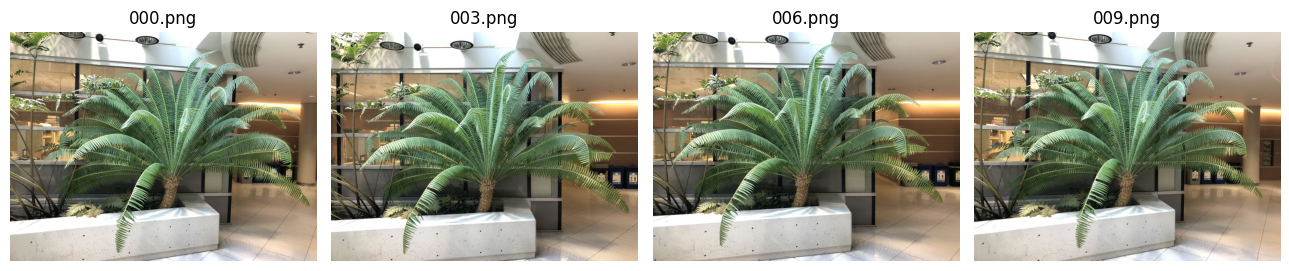

12 real photographs; seed=42; source revision=a288dd0f14786c93483e45524328726ab7b1b4ce


In [3]:
from pathlib import Path
import hashlib, json, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR = Path("data/fern/images")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_REVISION = "a288dd0f14786c93483e45524328726ab7b1b4ce"
IMAGE_NAMES = [f"{i:03d}.png" for i in range(12)]
data_manifest = []
for name in IMAGE_NAMES:
    url = f"https://raw.githubusercontent.com/facebookresearch/vggt/{DATA_REVISION}/examples/llff_fern/images/{name}"
    path = DATA_DIR / name
    if not path.exists():
        with urllib.request.urlopen(url, timeout=120) as response:
            payload = response.read()
        temporary = path.with_suffix(".download")
        temporary.write_bytes(payload)
        temporary.replace(path)
    with Image.open(path) as image:
        image.verify()
    data_manifest.append({"name": name, "url": url, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
image_paths = [DATA_DIR / name for name in IMAGE_NAMES]
Path("data/fern/manifest.json").write_text(json.dumps(data_manifest, indent=2))
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, path in zip(axes, image_paths[::3]):
    ax.imshow(Image.open(path)); ax.set_title(path.name); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"{len(image_paths)} real photographs; seed={SEED}; source revision={DATA_REVISION}")


### Runnable baseline — sparse COLMAP reconstruction

The pipeline is **SIFT extraction → exhaustive matching and geometric verification → incremental registration, triangulation and bundle adjustment**. Exhaustive matching tests every image pair; with 12 images there are 66 pairs.

We keep images at their original pixel dimensions (the extraction limit is 800 px), use a 512-feature target per image, and keep one shared camera. SIFT may keep more features around the cutoff because several orientations can share a detected scale/location. Completed results are reused only when the input hashes, feature budget, seed and PyCOLMAP version match. A changed configuration creates a fresh run directory. Pass `force=True` to deliberately recompute; the newest successful record replaces the old record with the same label. Bundle adjustment runs on the CPU in this teaching configuration.


In [4]:
from pathlib import Path
import hashlib, json, os, uuid
import numpy as np

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def latest_records(path):
    path = Path(path)
    records = json.loads(path.read_text()) if path.exists() else []
    if not isinstance(records, list):
        raise ValueError(f'Expected a list of run records: {path}')
    by_name = {}
    for row in records:
        if not isinstance(row, dict) or not isinstance(row.get('name'), str):
            raise ValueError(f'Invalid run record: {path}')
        by_name[row['name']] = row
    return list(by_name.values())

def save_record(path, record):
    rows = {row['name']: row for row in latest_records(path)}
    rows[record['name']] = record
    atomic_json(path, list(rows.values()))
    return list(rows.values())

def archive_working_files(destination, directories):
    import zipfile
    destination = Path(destination)
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for directory in directories:
            directory = Path(directory)
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith('.tmp'):
                    archive.write(path, path.absolute().relative_to(Path.cwd()))
    print('Saved', destination.name)
    return destination.name


def load_sfm_record(record):
    work = OUTPUT / record['work_directory']
    for name in ('cameras.txt', 'images.txt', 'points3D.txt', 'database.db'):
        if not (work/name).is_file():
            raise FileNotFoundError(f'Missing {work/name}. Restore the full baseline ZIP or recompute this configuration.')
    model = pycolmap.Reconstruction(str(work))
    info = dict(record['info'], database=str(work/'database.db'), work_directory=str(work))
    if model.num_reg_images() != info['registered_images'] or model.num_points3D() != info['points3D']:
        raise ValueError('Saved reconstruction and run record disagree')
    return model, info

OUTPUT = Path("lab07_outputs")
OUTPUT.mkdir(exist_ok=True)

def run_sfm(label, max_features=512, force=False):
    signature = {'features': int(max_features), 'seed': SEED, 'pycolmap': pycolmap.__version__,
                 'images': data_manifest, 'max_image_size': 800, 'camera_model': 'SIMPLE_RADIAL',
                 'single_camera': True, 'max_ratio': 0.8, 'sift_device': 'cpu'}
    saved = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(label)
    if not force and saved and saved['signature'] == signature:
        reconstruction, info = load_sfm_record(saved)
        print(f"Reused {label}; original pipeline time {info['total_s']:.3f} s ({info['sift_device']}).")
        return reconstruction, info
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f")
    work = OUTPUT / f"{label}_{stamp}"
    work.mkdir()
    db_path, sparse_dir = work / "database.db", work / "sparse"
    sparse_dir.mkdir()
    extraction = pycolmap.FeatureExtractionOptions()
    extraction.max_image_size = 800
    extraction.num_threads = 4
    extraction.use_gpu = False
    extraction.sift.max_num_features = max_features
    matching = pycolmap.FeatureMatchingOptions()
    matching.num_threads = 4
    matching.use_gpu = False
    matching.sift.max_ratio = 0.8
    options = pycolmap.IncrementalPipelineOptions()
    options.num_threads = 4
    options.random_seed = SEED
    options.min_model_size = 3
    options.ba_use_gpu = False
    pycolmap.set_random_seed(SEED)
    started = time.perf_counter()
    pycolmap.extract_features(str(db_path), str(DATA_DIR), image_names=IMAGE_NAMES,
        camera_mode=pycolmap.CameraMode.SINGLE, camera_model="SIMPLE_RADIAL",
        extraction_options=extraction, device=sfm_device)
    extracted = time.perf_counter()
    pycolmap.match_exhaustive(str(db_path), matching_options=matching, device=sfm_device)
    matched = time.perf_counter()
    maps = pycolmap.incremental_mapping(str(db_path), str(DATA_DIR), str(sparse_dir), options=options)
    finished = time.perf_counter()
    if not maps:
        raise RuntimeError("No reconstruction. Inspect overlap, texture and camera settings before changing thresholds.")
    reconstruction = max(maps.values(), key=lambda model: model.num_reg_images())
    reconstruction.write_text(str(work))
    reconstruction.export_PLY(str(OUTPUT / f"{label}_sparse.ply"))
    with sqlite3.connect(db_path) as connection:
        keypoint_counts = [row[0] for row in connection.execute("SELECT rows FROM keypoints")]
    info = {"label": label, "requested_features": max_features,
            "actual_keypoints_mean": float(np.mean(keypoint_counts)),
            "actual_keypoints_min": int(min(keypoint_counts)),
            "actual_keypoints_max": int(max(keypoint_counts)),
            "registered_images": reconstruction.num_reg_images(), "input_images": len(IMAGE_NAMES),
            "points3D": reconstruction.num_points3D(),
            "mean_reprojection_error_px": reconstruction.compute_mean_reprojection_error(),
            "mean_track_length": reconstruction.compute_mean_track_length(),
            "extraction_s": extracted-started, "matching_s": matched-extracted,
            "mapping_s": finished-matched, "total_s": finished-started,
            "sift_device": COLMAP_DEVICE, "bundle_adjustment_device": "cpu",
            "database": str(db_path), "work_directory": str(work)}
    save_record(OUTPUT/'run_records.json', {'name': label, 'signature': signature,
                'work_directory': work.name, 'info': info})
    atomic_json(OUTPUT/'baseline_state.json', {'seed': SEED, 'input_manifest': data_manifest,
                'python': platform.python_version(), 'pycolmap': pycolmap.__version__,
                'colmap_has_cuda': bool(pycolmap.has_cuda)})
    return reconstruction, info


baseline, baseline_info = run_sfm("baseline", max_features=512)
print(json.dumps(baseline_info, indent=2))
assert baseline.num_reg_images() >= 3 and baseline.num_points3D() > 0

I20261015 01:30:53.095393 0x16fcab000 misc.cc:44] 
Feature extraction
I20261015 01:30:53.098817 0x16ff67000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:53.099227 0x16fff3000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:53.099427 0x3104bb000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:53.099481 0x310547000 sift.cc:726] Creating SIFT CPU feature extractor


I20261015 01:30:53.823348 0x3105d3000 feature_extraction.cc:260] Processed file [1/12]
I20261015 01:30:53.823494 0x3105d3000 feature_extraction.cc:263]   Name:            001.png
I20261015 01:30:53.823569 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:53.823574 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:53.823580 0x3105d3000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:53.823587 0x3105d3000 feature_extraction.cc:282]   Features:        632 (SIFT)
I20261015 01:30:53.834113 0x3105d3000 feature_extraction.cc:260] Processed file [2/12]
I20261015 01:30:53.834142 0x3105d3000 feature_extraction.cc:263]   Name:            003.png
I20261015 01:30:53.834148 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:53.834152 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:53.834158 0x3105d3000 feature_extraction.cc:

I20261015 01:30:54.640813 0x3105d3000 feature_extraction.cc:260] Processed file [5/12]
I20261015 01:30:54.640845 0x3105d3000 feature_extraction.cc:263]   Name:            004.png
I20261015 01:30:54.640851 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:54.640855 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:54.640861 0x3105d3000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:54.640867 0x3105d3000 feature_extraction.cc:282]   Features:        632 (SIFT)
I20261015 01:30:54.649100 0x3105d3000 feature_extraction.cc:260] Processed file [6/12]
I20261015 01:30:54.649296 0x3105d3000 feature_extraction.cc:263]   Name:            005.png
I20261015 01:30:54.649303 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:54.649307 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:54.649313 0x3105d3000 feature_extraction.cc:

I20261015 01:30:55.307640 0x3105d3000 feature_extraction.cc:260] Processed file [9/12]
I20261015 01:30:55.307727 0x3105d3000 feature_extraction.cc:263]   Name:            008.png
I20261015 01:30:55.307739 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:55.307746 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:55.307752 0x3105d3000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:55.307758 0x3105d3000 feature_extraction.cc:282]   Features:        634 (SIFT)
I20261015 01:30:55.338098 0x3105d3000 feature_extraction.cc:260] Processed file [10/12]
I20261015 01:30:55.338132 0x3105d3000 feature_extraction.cc:263]   Name:            009.png
I20261015 01:30:55.338138 0x3105d3000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:55.338143 0x3105d3000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:55.338149 0x3105d3000 feature_extraction.cc

I20261015 01:30:55.511970 0x16fcab000 feature_matching.cc:117] in 0.116s
I20261015 01:30:55.512003 0x16fcab000 timer.cc:90] Elapsed time: 0.002 [minutes]
I20261015 01:30:55.515445 0x20c2622c0 incremental_pipeline.cc:264] Loading database
I20261015 01:30:55.516778 0x20c2622c0 database_cache.cc:67] Loading rigs...
I20261015 01:30:55.516823 0x20c2622c0 database_cache.cc:77]  1 in 0.000s
I20261015 01:30:55.516833 0x20c2622c0 database_cache.cc:85] Loading cameras...
I20261015 01:30:55.516847 0x20c2622c0 database_cache.cc:103]  1 in 0.000s
I20261015 01:30:55.516854 0x20c2622c0 database_cache.cc:111] Loading frames...
I20261015 01:30:55.516888 0x20c2622c0 database_cache.cc:126]  12 in 0.000s
I20261015 01:30:55.516895 0x20c2622c0 database_cache.cc:134] Loading matches...
I20261015 01:30:55.516979 0x20c2622c0 database_cache.cc:139]  66 in 0.000s
I20261015 01:30:55.516984 0x20c2622c0 database_cache.cc:155] Loading images...
I20261015 01:30:55.517273 0x20c2622c0 database_cache.cc:239]  12 in 0.00

I20261015 01:30:55.734678 0x20c2622c0 incremental_pipeline.cc:439] Registering image #1 (num_reg_frames=4)
I20261015 01:30:55.734697 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 164 / 351 points
I20261015 01:30:55.753284 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:55.795650 0x20c2622c0 incremental_pipeline.cc:439] Registering image #3 (num_reg_frames=5)
I20261015 01:30:55.795669 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 175 / 328 points
I20261015 01:30:55.823845 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:55.853079 0x20c2622c0 incremental_pipeline.cc:439] Registering image #10 (num_reg_frames=6)
I20261015 01:30:55.853096 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 171 / 338 points
I20261015 01:30:55.865949 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:55.901394 0x20c2622c0 incremental_p

I20261015 01:30:55.970307 0x20c2622c0 incremental_pipeline.cc:439] Registering image #8 (num_reg_frames=8)
I20261015 01:30:55.970326 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 150 / 329 points
I20261015 01:30:55.985273 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:56.036727 0x20c2622c0 incremental_pipeline.cc:439] Registering image #2 (num_reg_frames=9)
I20261015 01:30:56.036747 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 135 / 291 points
I20261015 01:30:56.053806 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:56.098478 0x20c2622c0 incremental_pipeline.cc:439] Registering image #5 (num_reg_frames=10)
I20261015 01:30:56.098498 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 174 / 326 points
I20261015 01:30:56.115388 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:56.148381 0x20c2622c0 incremental_p

{
  "label": "baseline",
  "requested_features": 512,
  "actual_keypoints_mean": 630.3333333333334,
  "actual_keypoints_min": 594,
  "actual_keypoints_max": 669,
  "registered_images": 12,
  "input_images": 12,
  "points3D": 570,
  "mean_reprojection_error_px": 0.8856061136534805,
  "mean_track_length": 4.7596491228070175,
  "extraction_s": 2.303642207989469,
  "matching_s": 0.12220408394932747,
  "mapping_s": 0.6974734158720821,
  "total_s": 3.1233197078108788,
  "sift_device": "cpu",
  "bundle_adjustment_device": "cpu",
  "database": "lab07_outputs/baseline_20261014T173053088692/database.db",
  "work_directory": "lab07_outputs/baseline_20261014T173053088692"
}


I20261015 01:30:56.173751 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:30:56.210201 0x20c2622c0 incremental_pipeline.cc:597] Keeping successful reconstruction
I20261015 01:30:56.210310 0x20c2622c0 timer.cc:90] Elapsed time: 0.012 [minutes]


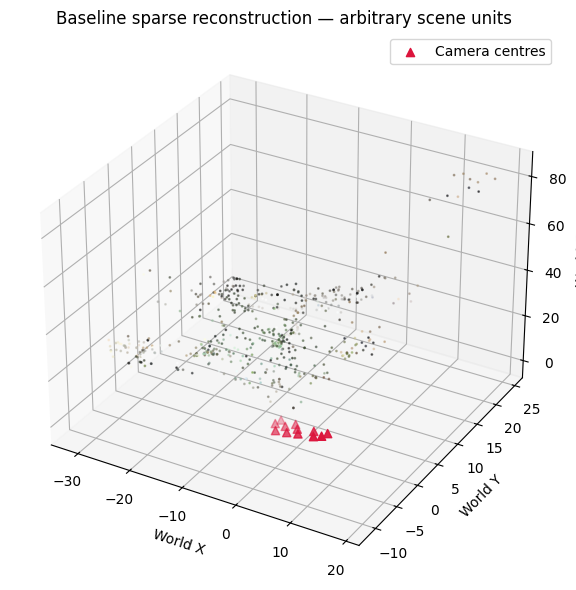

In [5]:
def plot_reconstruction(reconstruction, title):
    points = np.asarray([p.xyz for p in reconstruction.points3D.values()])
    colours = np.asarray([p.color for p in reconstruction.points3D.values()]) / 255.0
    cameras = np.asarray([image.projection_center() for image in reconstruction.images.values()
                          if image.has_pose])
    chosen = np.random.default_rng(SEED).choice(len(points), min(12000, len(points)), replace=False)
    fig = plt.figure(figsize=(10, 6)); ax = fig.add_subplot(111, projection="3d")
    ax.scatter(*points[chosen].T, c=colours[chosen], s=1, alpha=0.5)
    ax.scatter(*cameras.T, c="crimson", s=35, marker="^", label="Camera centres")
    ax.set(xlabel="World X", ylabel="World Y", zlabel="World Z", title=title)
    ax.legend(); plt.tight_layout()
    if 'QOUT' in globals():
        name = 'baseline_cloud.png' if title.startswith('Baseline') else 'feature4096_cloud.png'
        fig.savefig(QOUT/name, dpi=140, bbox_inches='tight')
    plt.show()

plot_reconstruction(baseline, "Baseline sparse reconstruction — arbitrary scene units")


### Save the baseline

Download this ZIP before leaving the session. It contains the complete reconstruction and verified-match database needed by the questions, plus the input photographs. The final export updates it with the feature-budget variant.

In [6]:
archive_working_files('colmap_baseline_submission.zip', [OUTPUT, Path('data/fern')])

Saved colmap_baseline_submission.zip


'colmap_baseline_submission.zip'

### Restore after a kernel restart

If you have restarted the kernel, run **only the next cell**, then your completed Q1–Q5 cells in order. It reads the saved reconstruction, database, input list and original timings. No feature extraction or reconstruction runs in this cell. If Q4 already completed, its matching saved variant is reused too; otherwise Q4 runs the one new configuration it asks for.

Keep the entire `lab07_outputs/` and `data/fern/` folders, or extract the baseline ZIP first. For a fresh machine, install the dependencies before restoring. Re-running a configuration replaces its record by label, so the comparison keeps one row per configuration.

In [ ]:
if globals().get('_RESTART_AFTER_INSTALL', False):
    raise RuntimeError('Restart the session after installation, then resume at Environment check or recovery.')

from pathlib import Path
import hashlib, json, os, uuid
import numpy as np

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def latest_records(path):
    path = Path(path)
    records = json.loads(path.read_text()) if path.exists() else []
    if not isinstance(records, list):
        raise ValueError(f'Expected a list of run records: {path}')
    by_name = {}
    for row in records:
        if not isinstance(row, dict) or not isinstance(row.get('name'), str):
            raise ValueError(f'Invalid run record: {path}')
        by_name[row['name']] = row
    return list(by_name.values())

def save_record(path, record):
    rows = {row['name']: row for row in latest_records(path)}
    rows[record['name']] = record
    atomic_json(path, list(rows.values()))
    return list(rows.values())

def archive_working_files(destination, directories):
    import zipfile
    destination = Path(destination)
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for directory in directories:
            directory = Path(directory)
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith('.tmp'):
                    archive.write(path, path.absolute().relative_to(Path.cwd()))
    print('Saved', destination.name)
    return destination.name


# Change WORK_DIR to the folder where you extracted colmap_baseline_submission.zip.
from pathlib import Path
import os, platform, sqlite3, time
from datetime import datetime, timezone
import cv2, pycolmap
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
WORK_DIR = Path.cwd()
os.chdir(WORK_DIR)
OUTPUT = Path('lab07_outputs')
if not (OUTPUT/'baseline_state.json').is_file():
    raise FileNotFoundError('Restore the complete baseline ZIP into WORK_DIR first.')
state = json.loads((OUTPUT/'baseline_state.json').read_text())
SEED, data_manifest = state['seed'], state['input_manifest']
DATA_DIR = Path('data/fern/images')
IMAGE_NAMES = [row['name'] for row in data_manifest]
image_paths = [DATA_DIR/name for name in IMAGE_NAMES]
for path, row in zip(image_paths, data_manifest):
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != row['sha256']:
        raise ValueError(f'Missing or changed input photograph: {path}')
COLMAP_DEVICE = "cpu"
sfm_device = pycolmap.Device.cpu
cv2.setRNGSeed(SEED)
pycolmap.set_random_seed(SEED)

from pathlib import Path
import hashlib, json, os, uuid
import numpy as np

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)

def latest_records(path):
    path = Path(path)
    records = json.loads(path.read_text()) if path.exists() else []
    if not isinstance(records, list):
        raise ValueError(f'Expected a list of run records: {path}')
    by_name = {}
    for row in records:
        if not isinstance(row, dict) or not isinstance(row.get('name'), str):
            raise ValueError(f'Invalid run record: {path}')
        by_name[row['name']] = row
    return list(by_name.values())

def save_record(path, record):
    rows = {row['name']: row for row in latest_records(path)}
    rows[record['name']] = record
    atomic_json(path, list(rows.values()))
    return list(rows.values())

def archive_working_files(destination, directories):
    import zipfile
    destination = Path(destination)
    with zipfile.ZipFile(destination, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        for directory in directories:
            directory = Path(directory)
            for path in sorted(directory.rglob('*')):
                if path.is_file() and not path.name.endswith('.tmp'):
                    archive.write(path, path.absolute().relative_to(Path.cwd()))
    print('Saved', destination.name)
    return destination.name


def load_sfm_record(record):
    work = OUTPUT / record['work_directory']
    for name in ('cameras.txt', 'images.txt', 'points3D.txt', 'database.db'):
        if not (work/name).is_file():
            raise FileNotFoundError(f'Missing {work/name}. Restore the full baseline ZIP or recompute this configuration.')
    model = pycolmap.Reconstruction(str(work))
    info = dict(record['info'], database=str(work/'database.db'), work_directory=str(work))
    if model.num_reg_images() != info['registered_images'] or model.num_points3D() != info['points3D']:
        raise ValueError('Saved reconstruction and run record disagree')
    return model, info

OUTPUT = Path("lab07_outputs")
OUTPUT.mkdir(exist_ok=True)

def run_sfm(label, max_features=512, force=False):
    signature = {'features': int(max_features), 'seed': SEED, 'pycolmap': pycolmap.__version__,
                 'images': data_manifest, 'max_image_size': 800, 'camera_model': 'SIMPLE_RADIAL',
                 'single_camera': True, 'max_ratio': 0.8, 'sift_device': 'cpu'}
    saved = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}.get(label)
    if not force and saved and saved['signature'] == signature:
        reconstruction, info = load_sfm_record(saved)
        print(f"Reused {label}; original pipeline time {info['total_s']:.3f} s ({info['sift_device']}).")
        return reconstruction, info
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f")
    work = OUTPUT / f"{label}_{stamp}"
    work.mkdir()
    db_path, sparse_dir = work / "database.db", work / "sparse"
    sparse_dir.mkdir()
    extraction = pycolmap.FeatureExtractionOptions()
    extraction.max_image_size = 800
    extraction.num_threads = 4
    extraction.use_gpu = False
    extraction.sift.max_num_features = max_features
    matching = pycolmap.FeatureMatchingOptions()
    matching.num_threads = 4
    matching.use_gpu = False
    matching.sift.max_ratio = 0.8
    options = pycolmap.IncrementalPipelineOptions()
    options.num_threads = 4
    options.random_seed = SEED
    options.min_model_size = 3
    options.ba_use_gpu = False
    pycolmap.set_random_seed(SEED)
    started = time.perf_counter()
    pycolmap.extract_features(str(db_path), str(DATA_DIR), image_names=IMAGE_NAMES,
        camera_mode=pycolmap.CameraMode.SINGLE, camera_model="SIMPLE_RADIAL",
        extraction_options=extraction, device=sfm_device)
    extracted = time.perf_counter()
    pycolmap.match_exhaustive(str(db_path), matching_options=matching, device=sfm_device)
    matched = time.perf_counter()
    maps = pycolmap.incremental_mapping(str(db_path), str(DATA_DIR), str(sparse_dir), options=options)
    finished = time.perf_counter()
    if not maps:
        raise RuntimeError("No reconstruction. Inspect overlap, texture and camera settings before changing thresholds.")
    reconstruction = max(maps.values(), key=lambda model: model.num_reg_images())
    reconstruction.write_text(str(work))
    reconstruction.export_PLY(str(OUTPUT / f"{label}_sparse.ply"))
    with sqlite3.connect(db_path) as connection:
        keypoint_counts = [row[0] for row in connection.execute("SELECT rows FROM keypoints")]
    info = {"label": label, "requested_features": max_features,
            "actual_keypoints_mean": float(np.mean(keypoint_counts)),
            "actual_keypoints_min": int(min(keypoint_counts)),
            "actual_keypoints_max": int(max(keypoint_counts)),
            "registered_images": reconstruction.num_reg_images(), "input_images": len(IMAGE_NAMES),
            "points3D": reconstruction.num_points3D(),
            "mean_reprojection_error_px": reconstruction.compute_mean_reprojection_error(),
            "mean_track_length": reconstruction.compute_mean_track_length(),
            "extraction_s": extracted-started, "matching_s": matched-extracted,
            "mapping_s": finished-matched, "total_s": finished-started,
            "sift_device": COLMAP_DEVICE, "bundle_adjustment_device": "cpu",
            "database": str(db_path), "work_directory": str(work)}
    save_record(OUTPUT/'run_records.json', {'name': label, 'signature': signature,
                'work_directory': work.name, 'info': info})
    atomic_json(OUTPUT/'baseline_state.json', {'seed': SEED, 'input_manifest': data_manifest,
                'python': platform.python_version(), 'pycolmap': pycolmap.__version__,
                'colmap_has_cuda': bool(pycolmap.has_cuda)})
    return reconstruction, info


def plot_reconstruction(reconstruction, title):
    points = np.asarray([p.xyz for p in reconstruction.points3D.values()])
    colours = np.asarray([p.color for p in reconstruction.points3D.values()]) / 255.0
    cameras = np.asarray([image.projection_center() for image in reconstruction.images.values()
                          if image.has_pose])
    chosen = np.random.default_rng(SEED).choice(len(points), min(12000, len(points)), replace=False)
    fig = plt.figure(figsize=(10, 6)); ax = fig.add_subplot(111, projection="3d")
    ax.scatter(*points[chosen].T, c=colours[chosen], s=1, alpha=0.5)
    ax.scatter(*cameras.T, c="crimson", s=35, marker="^", label="Camera centres")
    ax.set(xlabel="World X", ylabel="World Y", zlabel="World Z", title=title)
    ax.legend(); plt.tight_layout()
    if 'QOUT' in globals():
        name = 'baseline_cloud.png' if title.startswith('Baseline') else 'feature4096_cloud.png'
        fig.savefig(QOUT/name, dpi=140, bbox_inches='tight')
    plt.show()


records = {r['name']: r for r in latest_records(OUTPUT/'run_records.json')}
if 'baseline' not in records:
    raise FileNotFoundError('No completed baseline record. Run the supplied baseline first.')
baseline, baseline_info = load_sfm_record(records['baseline'])
if 'feature4096' in records:
    variant, variant_info = load_sfm_record(records['feature4096'])
print('Restored reconstruction, database, original timings and latest records. Continue with Q1–Q5.')

## Q1 — Matching and robust geometry (20 points)

### Q1.1 Lowe's ratio test (12 points)
OpenCV supplies the two nearest descriptor neighbours for each feature. Retain a match if $d_1 < r d_2$, using $r=0.75$. Handle entries with fewer than two neighbours and do not modify the input. Return a list of `cv2.DMatch` objects.

This exercise uses OpenCV SIFT to expose the matching steps; it is separate from the COLMAP database pipeline. A descriptor match is only a candidate correspondence.


In [7]:
QOUT = Path('tutorial07_question_results'); QOUT.mkdir(exist_ok=True)

In [8]:
image0, image1 = [cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) for path in image_paths[:2]]
sift = cv2.SIFT_create(nfeatures=2048)
keypoints0, descriptors0 = sift.detectAndCompute(image0, None)
keypoints1, descriptors1 = sift.detectAndCompute(image1, None)
knn_matches = cv2.BFMatcher(cv2.NORM_L2).knnMatch(descriptors0, descriptors1, k=2)
print("Detected features:", len(keypoints0), len(keypoints1))


Detected features: 1982 1936


In [9]:
def ratio_test(knn_matches, ratio=0.75):
    ###YOUR CODE HERE###
    ratio = float(ratio)
    if not (np.isfinite(ratio) and 0 < ratio <= 1):
        raise ValueError(f"ratio must lie in (0, 1], got {ratio}")
    good = []
    for neighbours in knn_matches:
        if len(neighbours) < 2:  # no second neighbour, so the ratio is undefined
            continue
        best, second = neighbours[0], neighbours[1]
        if best.distance < ratio * second.distance:
            good.append(best)  # keep the original DMatch; the input is not modified
    return good

good = ratio_test(knn_matches)
assert len(good) >= 8, "Not enough correspondences for fundamental-matrix estimation."
points0 = np.float64([keypoints0[m.queryIdx].pt for m in good])
points1 = np.float64([keypoints1[m.trainIdx].pt for m in good])
print("Ratio-test matches:", len(good))


Ratio-test matches: 401


### Q1.2 Sampson error and RANSAC (8 points)

For homogeneous image points $x_0,x_1$ and $x_1^\top F x_0=0$, implement the squared Sampson distance:
$$d_S^2 = \frac{(x_1^\top F x_0)^2}{(Fx_0)_1^2+(Fx_0)_2^2+(F^\top x_1)_1^2+(F^\top x_1)_2^2}.$$
Return one value per pair. Because F is defined only up to a nonzero scale, your result must be invariant to multiplying F by a nonzero scalar. Normalize F before computation, reject a zero/non-finite F, and return infinity for a zero denominator. The values have approximate squared-pixel units. Explain why a stricter ratio test does not replace geometric verification.


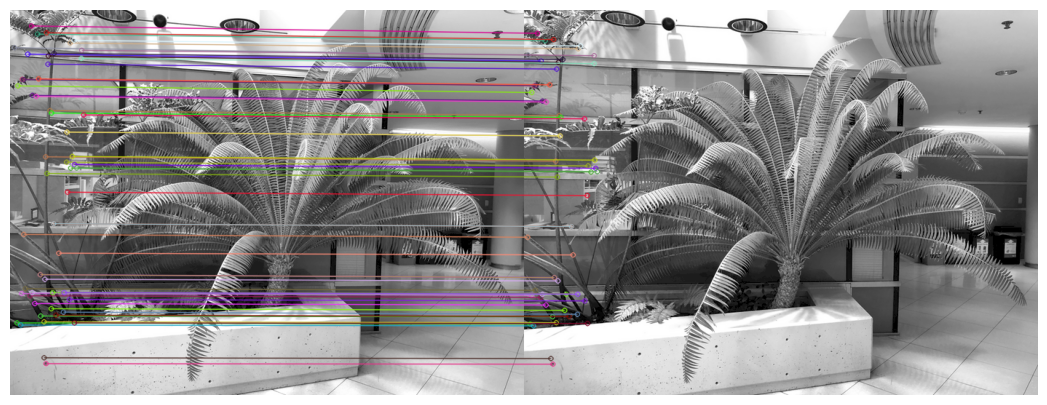

{'candidates': 401, 'inliers': 345, 'inlier_ratio': 0.8603491271820449, 'median_inlier_sampson_px2': 0.04128719980731682}


In [10]:
def sampson_squared(F, p0, p1):
    ###YOUR CODE HERE###
    F = np.asarray(F, dtype=np.float64)
    if F.shape != (3, 3) or not np.all(np.isfinite(F)):
        raise ValueError("F must be a finite 3x3 matrix")
    scale = np.linalg.norm(F)
    if scale == 0:
        raise ValueError("F must be nonzero")
    F = F / scale  # F is defined only up to scale
    p0, p1 = np.asarray(p0, dtype=np.float64), np.asarray(p1, dtype=np.float64)
    if p0.ndim != 2 or p0.shape[1] != 2 or p0.shape != p1.shape:
        raise ValueError("p0 and p1 must both have shape (N, 2)")
    x0 = np.column_stack([p0, np.ones(len(p0))])
    x1 = np.column_stack([p1, np.ones(len(p1))])
    Fx0 = x0 @ F.T          # rows are F x0
    Ftx1 = x1 @ F           # rows are F^T x1
    numerator = np.sum(x1 * Fx0, axis=1) ** 2
    denominator = Fx0[:, 0]**2 + Fx0[:, 1]**2 + Ftx1[:, 0]**2 + Ftx1[:, 1]**2
    distances = np.full(len(p0), np.inf)
    valid = denominator > 0
    distances[valid] = numerator[valid] / denominator[valid]
    return distances

cv2.setRNGSeed(SEED)
F, inlier_mask = cv2.findFundamentalMat(points0, points1, cv2.FM_RANSAC, 1.5, 0.999)
assert F is not None and F.shape == (3, 3)
inliers = inlier_mask.ravel().astype(bool)
distances = sampson_squared(F, points0, points1)
assert np.all(np.isfinite(distances)) and np.all(distances >= 0)
verified = [m for m, keep in zip(good, inliers) if keep]
canvas = cv2.drawMatches(image0, keypoints0, image1, keypoints1, verified[:60], None,
                         flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14, 5)); plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.savefig(QOUT/'figure_19.png', dpi=140, bbox_inches='tight'); plt.show()
print({"candidates": len(good), "inliers": int(inliers.sum()),
       "inlier_ratio": float(inliers.mean()), "median_inlier_sampson_px2": float(np.median(distances[inliers]))})


**Your answer:**

The ratio test is a *per-feature appearance* test: it keeps a match when the nearest descriptor is clearly closer than the second nearest. It never checks whether the matches agree with one rigid camera motion. Fern leaflets are highly self-similar, so a feature can match a *distinctive but wrong* leaflet and still pass. Tightening $r$ throws away true matches along with false ones, but it cannot remove outliers that look right and are geometrically wrong.

Geometric verification adds the missing *global* constraint: every inlier must satisfy the same epipolar geometry $x_1^\top F x_0 = 0$, estimated robustly by RANSAC. Here 401 ratio-test candidates gave 345 RANSAC inliers (86%). So 56 matches that passed the ratio test are still inconsistent with the two-view geometry. The median inlier squared Sampson distance is 0.041 px² (≈0.2 px), which shows the remaining matches fit $F$ tightly.

## Q2 — Projection and triangulation (25 points)

COLMAP uses a world-to-camera pose: $X_c=RX_w+t$. The camera centre in world coordinates is $C=-R^\top t$. Pixel axes follow the OpenCV convention: x right, y down, z forward.

### Q2.1 Camera centre and projection (12 points)
Implement both functions. `project_pinhole` takes undistorted 3D world points and returns `(pixels, camera_z)`. Divide only where `z > 0`; use `NaN` pixels for points behind the camera. Distortion is deliberately absent in this synthetic exercise. For the real COLMAP model, use the camera's projection API.


In [11]:
def camera_center(R, t):
    ###YOUR CODE HERE###
    R, t = np.asarray(R, dtype=np.float64), np.asarray(t, dtype=np.float64).reshape(3)
    return -R.T @ t

def project_pinhole(world_points, K, R, t):
    ###YOUR CODE HERE###
    X = np.asarray(world_points, dtype=np.float64).reshape(-1, 3)
    R, t = np.asarray(R, dtype=np.float64), np.asarray(t, dtype=np.float64).reshape(3)
    camera_points = X @ R.T + t          # X_c = R X_w + t
    camera_z = camera_points[:, 2]
    homogeneous = camera_points @ np.asarray(K, dtype=np.float64).T
    pixels = np.full((len(X), 2), np.nan)
    front = camera_z > 0                 # divide only for points in front of the camera
    pixels[front] = homogeneous[front, :2] / homogeneous[front, 2:3]
    return pixels, camera_z

K = np.array([[500., 0, 320], [0, 500., 240], [0, 0, 1.]])
R0, t0 = np.eye(3), np.zeros(3)
R1, t1 = np.eye(3), np.array([-0.3, 0., 0.])
known_points = np.array([[-0.4, -0.2, 3.], [0.2, 0.3, 4.], [0., 0., 2.5], [0.4, -0.3, 5.]])
uv0, z0 = project_pinhole(known_points, K, R0, t0)
uv1, z1 = project_pinhole(known_points, K, R1, t1)
assert np.allclose(camera_center(R1, t1), [0.3, 0, 0])
assert np.allclose(uv0[2], [320, 240])
print("Camera centres:", camera_center(R0,t0), camera_center(R1,t1))


Camera centres: [0. 0. 0.] [0.3 0.  0. ]


### Q2.2 Linear triangulation (8 points)
For each correspondence, stack the four constraints $uP_3-P_1$ and $vP_3-P_2$ for the two cameras. Use the last right singular vector of this $4\times4$ matrix, then dehomogenize. Return `(N,3)` points. Reject a near-zero homogeneous denominator. The supplied points have exact known geometry so this check has an actual ground truth.


In [12]:
def triangulate_dlt(P0, P1, pixels0, pixels1):
    ###YOUR CODE HERE###
    P0, P1 = np.asarray(P0, dtype=np.float64), np.asarray(P1, dtype=np.float64)
    pixels0 = np.asarray(pixels0, dtype=np.float64).reshape(-1, 2)
    pixels1 = np.asarray(pixels1, dtype=np.float64).reshape(-1, 2)
    if P0.shape != (3, 4) or P1.shape != (3, 4) or len(pixels0) != len(pixels1):
        raise ValueError("Expected two 3x4 projections and matching (N, 2) pixel arrays")
    points = np.empty((len(pixels0), 3))
    for i, ((u0, v0), (u1, v1)) in enumerate(zip(pixels0, pixels1)):
        A = np.stack([u0 * P0[2] - P0[0], v0 * P0[2] - P0[1],
                      u1 * P1[2] - P1[0], v1 * P1[2] - P1[1]])
        X = np.linalg.svd(A)[2][-1]      # last right singular vector
        if abs(X[3]) < 1e-12 * np.linalg.norm(X):
            raise ValueError(f"Correspondence {i} triangulates to a point at infinity")
        points[i] = X[:3] / X[3]
    return points

P0, P1 = K @ np.column_stack([R0,t0]), K @ np.column_stack([R1,t1])
recovered = triangulate_dlt(P0, P1, uv0, uv1)
assert np.allclose(recovered, known_points, atol=1e-8)
print("Synthetic reconstruction max error:", np.max(np.abs(recovered-known_points)))


Synthetic reconstruction max error: 1.1546319456101628e-14


### Q2.3 Scale and degeneracy (5 points)
Explain why monocular SfM cannot recover metres without an external scale, and why walking sideways usually improves depth recovery compared with rotating a camera about its optical centre.


**Your answer:**

**Scale.** A projection $x \sim K(RX+t)$ is unchanged if we replace $X \to sX$ and $t \to st$. The same holds more generally for any similarity transform of the whole scene and cameras. Images alone therefore fix geometry only up to a 7-DoF similarity, so COLMAP's units are arbitrary. Metric scale needs external information: a known distance or object size, a calibrated stereo baseline, or GPS/IMU.

**Sideways vs. rotation.** Depth comes from *parallax*: the same point seen from two different centres, where disparity ≈ baseline × focal / depth. Walking sideways creates a baseline, so rays from the two views meet at a usable angle and triangulation is well conditioned. Rotating about the optical centre gives zero baseline. The views are then related by the depth-independent homography $H = KRK^{-1}$, the two rays are the same line, and $E = [t]_\times R = 0$, so depth is unobservable. A small baseline gives nearly parallel rays and large depth uncertainty.

## Q3 — Reconstruction diagnostics (25 points)

### Q3.1 Match graph (12 points)
Read COLMAP's geometrically verified pair table and build a symmetric adjacency matrix. An edge means at least 30 verified correspondences. Return image names, the matrix, and node degrees. Image IDs are not guaranteed to be contiguous. Use `pycolmap.pair_id_to_image_pair` to decode pair IDs.


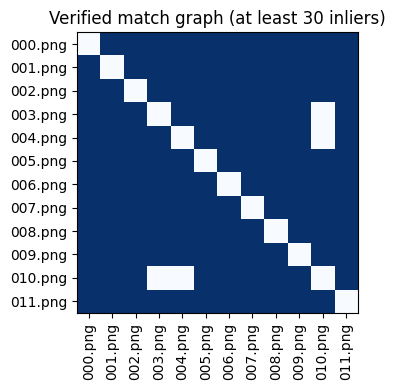

{'000.png': 11, '001.png': 11, '002.png': 11, '003.png': 10, '004.png': 10, '005.png': 11, '006.png': 11, '007.png': 11, '008.png': 11, '009.png': 11, '010.png': 9, '011.png': 11}


In [13]:
def verified_graph(database_path, min_inliers=30):
    ###YOUR CODE HERE###
    with sqlite3.connect(str(database_path)) as connection:
        images = connection.execute("SELECT image_id, name FROM images ORDER BY name").fetchall()
        pairs = connection.execute("SELECT pair_id, rows FROM two_view_geometries").fetchall()
    names = [name for _, name in images]
    index = {image_id: i for i, (image_id, _) in enumerate(images)}  # IDs need not be contiguous
    graph = np.zeros((len(names), len(names)), dtype=int)
    for pair_id, num_inliers in pairs:
        if num_inliers is None or num_inliers < min_inliers:
            continue
        id0, id1 = pycolmap.pair_id_to_image_pair(int(pair_id))
        a, b = index[int(id0)], index[int(id1)]
        if a != b:
            graph[a, b] = graph[b, a] = 1
    return names, graph, graph.sum(axis=1)

graph_names, graph, degrees = verified_graph(baseline_info["database"])
assert np.array_equal(graph, graph.T) and not np.any(np.diag(graph))
plt.figure(figsize=(5,4)); plt.imshow(graph, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(graph_names)), graph_names, rotation=90); plt.yticks(range(len(graph_names)), graph_names)
plt.title("Verified match graph (at least 30 inliers)"); plt.tight_layout(); plt.savefig(QOUT/'figure_28.png', dpi=140, bbox_inches='tight'); plt.show()
print(dict(zip(graph_names, degrees.tolist())))


### Q3.2 Track support and filtering (8 points)
Implement a mask selecting 3D points with a track length of at least 3 and mean reprojection error no larger than 1 pixel. Return the selected point IDs. Do not mutate the reconstruction. Plot error and track-length distributions and report the retained fraction. A point's `error` is its stored mean reprojection error; it is not a per-observation RMSE.


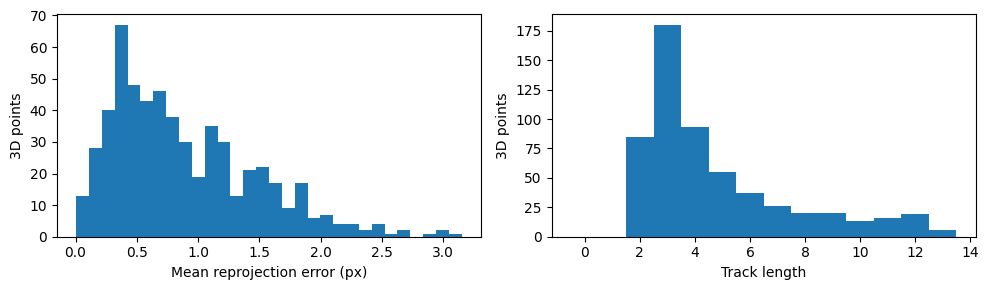

Retained fraction: 0.5333333333333333


In [14]:
def reliable_point_ids(reconstruction, min_track=3, max_error=1.0):
    ###YOUR CODE HERE###
    # Read-only pass over the points; the reconstruction is not modified.
    return [point_id for point_id, point in reconstruction.points3D.items()
            if point.track.length() >= min_track and point.error <= max_error]

retained_ids = reliable_point_ids(baseline)
errors = np.array([p.error for p in baseline.points3D.values()])
lengths = np.array([p.track.length() for p in baseline.points3D.values()])
fig, axes = plt.subplots(1,2,figsize=(10,3))
axes[0].hist(errors, bins=30); axes[0].set(xlabel="Mean reprojection error (px)",ylabel="3D points")
axes[1].hist(lengths, bins=np.arange(lengths.max()+2)-0.5); axes[1].set(xlabel="Track length",ylabel="3D points")
plt.tight_layout(); plt.savefig(QOUT/'figure_30.png', dpi=140, bbox_inches='tight'); plt.show()
retained_fraction = len(retained_ids)/baseline.num_points3D()
print("Retained fraction:", retained_fraction)


### Q3.3 Bundle adjustment and diagnostic limits (5 points)
State what bundle adjustment optimizes. Can a lower reprojection error after removing most points prove that a reconstruction became more accurate? Explain using both coverage and fit.


**Your answer:**

Bundle adjustment jointly refines all camera poses $(R_i, t_i)$, the intrinsics (here a shared focal length, principal point and one radial-distortion term) and all 3D points $X_j$. It minimises the robust sum of squared reprojection errors $\sum_{ij} \rho\big(\lVert \pi(K, R_i, t_i, X_j) - x_{ij} \rVert^2\big)$ over the observed keypoints.

**No.** A lower error after removing points does not prove higher accuracy:
- **Fit is circular.** Reprojection error is measured on the same observations that bundle adjustment fitted. Filtering by error keeps the low-error points by construction. Our filter kept only 53% of the points (304/570), so the mean error must fall even if no camera or point moved closer to the truth. Short tracks (2 views) can be fitted almost exactly whether or not they are correct.
- **Coverage drops.** Fewer points mean less of the scene is represented and fewer observations constrain each camera. That can make poses *less* reliable and leave holes.

Accuracy needs independent evidence, such as ground-truth poses or known distances, or held-out views. Fit (error), coverage (registered images, points) and track length should be reported together.

## Q4 — Controlled feature-budget experiment (20 points)

### Q4.1 Run one controlled variant (12 points)
**Hypothesis:** increasing the SIFT feature budget may increase reconstruction coverage at additional matching cost. Compare 512 versus 4,096 requested features, keeping images, camera model, seed, image-size limit, matching settings and device fixed. Use a fresh database through `run_sfm`. Complete the configuration below, run the variant, and generate a table from real measurements. Also check the actual keypoint counts in the database: an increased target need not yield more features. A slower or worse result is valid evidence; do not invent an improvement.


I20261015 01:30:57.835955 0x32c59f000 misc.cc:44] 
Feature extraction
I20261015 01:30:57.836165 0x32c85b000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:57.836185 0x32c8e7000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:57.836203 0x32c973000 sift.cc:726] Creating SIFT CPU feature extractor
I20261015 01:30:57.836223 0x32c9ff000 sift.cc:726] Creating SIFT CPU feature extractor


I20261015 01:30:58.540211 0x32ca8b000 feature_extraction.cc:260] Processed file [1/12]
I20261015 01:30:58.540244 0x32ca8b000 feature_extraction.cc:263]   Name:            000.png
I20261015 01:30:58.540250 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:58.540254 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:58.540259 0x32ca8b000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:58.540266 0x32ca8b000 feature_extraction.cc:282]   Features:        2609 (SIFT)
I20261015 01:30:58.545529 0x32ca8b000 feature_extraction.cc:260] Processed file [2/12]
I20261015 01:30:58.545559 0x32ca8b000 feature_extraction.cc:263]   Name:            002.png
I20261015 01:30:58.545565 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:58.545570 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:58.545575 0x32ca8b000 feature_extraction.cc

I20261015 01:30:59.204377 0x32ca8b000 feature_extraction.cc:260] Processed file [5/12]
I20261015 01:30:59.204411 0x32ca8b000 feature_extraction.cc:263]   Name:            006.png
I20261015 01:30:59.204417 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:59.204422 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:59.204427 0x32ca8b000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:59.204433 0x32ca8b000 feature_extraction.cc:282]   Features:        2631 (SIFT)
I20261015 01:30:59.214495 0x32ca8b000 feature_extraction.cc:260] Processed file [6/12]
I20261015 01:30:59.214534 0x32ca8b000 feature_extraction.cc:263]   Name:            005.png
I20261015 01:30:59.214541 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:59.214545 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:59.214550 0x32ca8b000 feature_extraction.cc

I20261015 01:30:59.940063 0x32ca8b000 feature_extraction.cc:260] Processed file [9/12]
I20261015 01:30:59.940163 0x32ca8b000 feature_extraction.cc:263]   Name:            008.png
I20261015 01:30:59.940178 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:59.940182 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:59.940185 0x32ca8b000 feature_extraction.cc:278]   Focal Length:    847.20px
I20261015 01:30:59.940189 0x32ca8b000 feature_extraction.cc:282]   Features:        2750 (SIFT)
I20261015 01:30:59.965443 0x32ca8b000 feature_extraction.cc:260] Processed file [10/12]
I20261015 01:30:59.965475 0x32ca8b000 feature_extraction.cc:263]   Name:            009.png
I20261015 01:30:59.965481 0x32ca8b000 feature_extraction.cc:272]   Dimensions:      706 x 529
I20261015 01:30:59.965485 0x32ca8b000 feature_extraction.cc:275]   Camera:          #1 - SIMPLE_RADIAL
I20261015 01:30:59.965490 0x32ca8b000 feature_extraction.c

I20261015 01:31:00.661240 0x32c59f000 feature_matching.cc:117] in 0.621s
I20261015 01:31:00.661261 0x32c59f000 timer.cc:90] Elapsed time: 0.010 [minutes]
I20261015 01:31:00.664559 0x20c2622c0 incremental_pipeline.cc:264] Loading database
I20261015 01:31:00.665704 0x20c2622c0 database_cache.cc:67] Loading rigs...
I20261015 01:31:00.665731 0x20c2622c0 database_cache.cc:77]  1 in 0.000s
I20261015 01:31:00.665738 0x20c2622c0 database_cache.cc:85] Loading cameras...
I20261015 01:31:00.665746 0x20c2622c0 database_cache.cc:103]  1 in 0.000s
I20261015 01:31:00.665749 0x20c2622c0 database_cache.cc:111] Loading frames...
I20261015 01:31:00.665775 0x20c2622c0 database_cache.cc:126]  12 in 0.000s
I20261015 01:31:00.665779 0x20c2622c0 database_cache.cc:134] Loading matches...
I20261015 01:31:00.665956 0x20c2622c0 database_cache.cc:139]  66 in 0.000s
I20261015 01:31:00.665962 0x20c2622c0 database_cache.cc:155] Loading images...
I20261015 01:31:00.666568 0x20c2622c0 database_cache.cc:239]  12 in 0.00

I20261015 01:31:00.948159 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:31:01.045694 0x20c2622c0 incremental_pipeline.cc:439] Registering image #2 (num_reg_frames=4)
I20261015 01:31:01.045714 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 429 / 1023 points
I20261015 01:31:01.139674 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment


... (2 outputs left out)

I20261015 01:31:01.647031 0x20c2622c0 incremental_pipeline.cc:439] Registering image #11 (num_reg_frames=8)
I20261015 01:31:01.647053 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 612 / 1071 points
I20261015 01:31:01.701626 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:31:01.800426 0x20c2622c0 incremental_pipeline.cc:439] Registering image #5 (num_reg_frames=9)
I20261015 01:31:01.800446 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 584 / 1059 points


I20261015 01:31:01.864454 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:31:01.946576 0x20c2622c0 incremental_pipeline.cc:439] Registering image #7 (num_reg_frames=10)
I20261015 01:31:01.946595 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 518 / 1094 points
I20261015 01:31:02.011174 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment


I20261015 01:31:02.114559 0x20c2622c0 incremental_pipeline.cc:439] Registering image #6 (num_reg_frames=11)
I20261015 01:31:02.114580 0x20c2622c0 incremental_pipeline.cc:442] => Image sees 635 / 1032 points
I20261015 01:31:02.184406 0x20c2622c0 incremental_pipeline.cc:43] Retriangulation and Global bundle adjustment
I20261015 01:31:02.308335 0x20c2622c0 incremental_pipeline.cc:597] Keeping successful reconstruction
I20261015 01:31:02.308528 0x20c2622c0 timer.cc:90] Elapsed time: 0.027 [minutes]


 Features   Images    Points   Error px    Track    Seconds
      512       12       570     0.8856     4.76       3.12
     4096       12      1757     0.6157     5.08       4.48


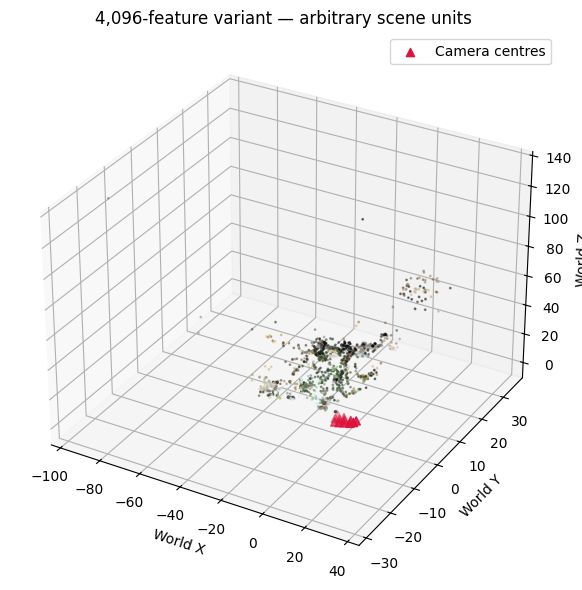

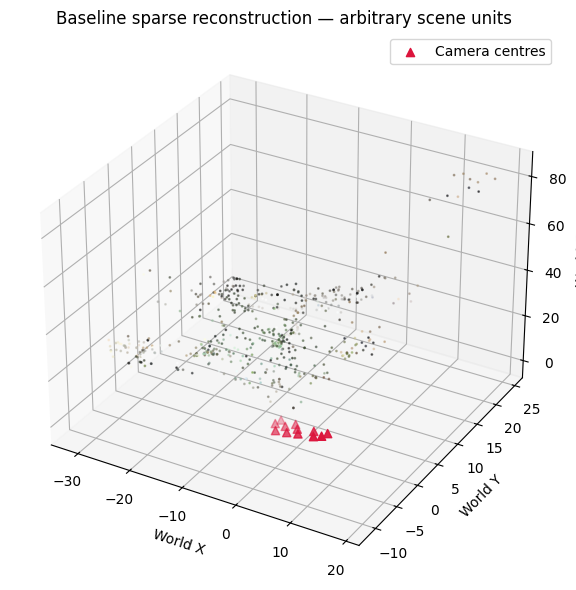

In [15]:
###YOUR CODE HERE###
variant_features = 4096  # Only the SIFT budget changes; every other setting stays as in run_sfm.
if variant_features is None:
    raise NotImplementedError("Q4.1: set the variant feature budget")
variant, variant_info = run_sfm("feature4096", max_features=variant_features)
comparison = [baseline_info, variant_info]
print(f"{'Features':>9} {'Images':>8} {'Points':>9} {'Error px':>10} {'Track':>8} {'Seconds':>10}")
for row in comparison:
    print(f"{row['requested_features']:9d} {row['registered_images']:8d} {row['points3D']:9d} "
          f"{row['mean_reprojection_error_px']:10.4f} {row['mean_track_length']:8.2f} {row['total_s']:10.2f}")
plot_reconstruction(variant, "4,096-feature variant — arbitrary scene units")
plot_reconstruction(baseline, "Baseline sparse reconstruction — arbitrary scene units")  # re-plot now that QOUT exists, so baseline_cloud.png is exported


### Q4.2 Interpret the comparison (8 points)
Use your table to discuss the coverage/fit/runtime trade-off. Name one confound in timing a single run and one failure mode that more features cannot solve. Do not compare raw coordinates between two SfM reconstructions without similarity alignment.


**Your answer:**

| Requested | Actual keypoints (mean, min–max) | Images | Points | Error (px) | Track | Total s (match / map) |
|---:|---:|---:|---:|---:|---:|---:|
| 512 | 630 (594–669) | 12/12 | 570 | 0.886 | 4.76 | 3.12 (0.12 / 0.70) |
| 4096 | 2712 (2533–3194) | 12/12 | 1757 | 0.616 | 5.08 | 4.48 (0.63 / 1.65) |

- **Budget ≠ features.** Requesting 4,096 gave only about 2,712 keypoints per image, because the 800-px images and SIFT's contrast threshold limit detection. The effective increase is about 4.3×, not 8×.
- **Coverage.** Registration was already saturated (12/12 in both runs), so the gain is density: 3.1× more sparse points and slightly longer tracks.
- **Fit.** Mean reprojection error fell from 0.886 to 0.616 px. This is internal fit only, not proof of more accurate geometry.
- **Runtime.** Total time rose 1.4×. Matching rose about 5× because exhaustive matching grows with the product of the two images' feature counts, and mapping and bundle adjustment rose about 2.4×.

**Timing confound.** This was a single run per setting. The baseline ran first and absorbed first-use initialisation: its extraction took 2.30 s, slower than the 4,096 run's 2.21 s despite fewer features. Background load and thread scheduling also vary. Even the counts are not exactly reproducible: an earlier identical baseline run gave 565 points rather than 570, because multithreaded mapping is not fully deterministic. Repeated runs would be needed before ranking speed or small differences.

**Failure mode more features cannot fix.** A lack of parallax, as in pure rotation or a tiny baseline, leaves depth unobservable however many points are matched. Repetitive or textureless surfaces and moving leaves are similar limits.

The two models have independent gauges, so their raw coordinates must not be compared without a Sim(3) alignment.

## Q5 — Capture design and bridge to learned geometry (10 points)

Propose a capture plan for a small object (5 points). Then contrast classical SfM with a feed-forward geometry model such as VGGT and explain how either could initialize later NeRF/3DGS work (5 points). Mention one failure case for each approach.


**Your answer:**

**Capture plan (small object).**
1. Static, matte object on a textured base (patterned mat or newspaper). Avoid shiny or transparent surfaces, or use a dulling spray.
2. Move the camera, not the object. On a turntable the static background contradicts the object's motion.
3. Orbit at 2–3 heights (≈0°, 30°, 60°) with a shot every 10–15°, about 60–90 images with ≥60–70% overlap. Add close-ups with sideways steps for parallax, never pure rotation.
4. Use one camera with fixed zoom and locked focus and exposure, so a shared camera model holds. Light it diffusely with no flash, and keep images sharp (f/8, fast shutter or a tripod).
5. Put a ruler or a marker of known size in view to fix metric scale, and check on site that every image registers and the match graph is connected.

**Classical SfM vs. VGGT.** COLMAP detects features, verifies them geometrically, and triangulates and bundle-adjusts incrementally. It is explicit, accurate and well diagnosed, and it scales to many images. It needs texture, overlap and parallax, and it is slow on large sets.
*Failure:* textureless, reflective or repetitive objects, or too few views, give no initial pair or wrong registrations.

VGGT is a feed-forward transformer. It predicts cameras, depth maps and point maps for a set of views in one pass, in seconds on a GPU. It works with few, low-overlap views and gives dense output. Its geometry comes from a learned prior with no guaranteed multi-view consistency, scale is still arbitrary, and GPU memory limits the number of views.
*Failure:* out-of-distribution scenes, such as unusual materials or extreme lighting, can yield confident but wrong or inconsistent depth.

**Bridge to NeRF/3DGS.** Both need camera poses and intrinsics. 3DGS also initialises its Gaussians, both position and colour, from a point cloud. COLMAP provides accurate poses plus the sparse `points3D`/PLY. VGGT provides fast poses plus dense, confidence-filtered point maps, ideally refined with bundle adjustment first. Pose errors from either source propagate into blur and floaters.

### Export question results

Run after completing Q1–Q5. Download both result ZIPs. Figures and the comparison table are included; your written answers remain in the completed notebook.

In [16]:
report = {"lab": 7, "seed": SEED, "python": json.loads((OUTPUT/"baseline_state.json").read_text())["python"],
          "pycolmap": pycolmap.__version__, "colmap_has_cuda": json.loads((OUTPUT/"baseline_state.json").read_text())["colmap_has_cuda"],
          "comparison": comparison, "ratio_test_matches": len(good),
          "ransac_inliers": int(inliers.sum()), "reliable_point_fraction": retained_fraction,
          "input_manifest": data_manifest,
          "evaluation_note": "Real-image internal diagnostics; no ground-truth 3D accuracy claim."}
(OUTPUT/"report.json").write_text(json.dumps(report, indent=2))
print("Saved", OUTPUT/"report.json", "and", OUTPUT/"baseline_sparse.ply")

import csv, shutil
QOUT = Path('tutorial07_question_results'); QOUT.mkdir(exist_ok=True)
shutil.copy2(OUTPUT/'report.json', QOUT/'report.json')
with (QOUT/'feature_comparison.csv').open('w', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(comparison[0]))
    writer.writeheader(); writer.writerows(comparison)
for path in Path('tutorial07_question_results').glob('*.png'):
    assert path.stat().st_size > 0
archive_working_files('colmap_baseline_submission.zip', [OUTPUT, Path('data/fern')])
archive_working_files('tutorial07_question_results.zip', [QOUT])

Saved lab07_outputs/report.json and lab07_outputs/baseline_sparse.ply


Saved colmap_baseline_submission.zip
Saved tutorial07_question_results.zip


'tutorial07_question_results.zip'

### References and troubleshooting

- [COLMAP documentation](https://colmap.github.io/tutorial.html) and [camera/output conventions](https://colmap.github.io/format.html).
- [PyCOLMAP](https://colmap.github.io/pycolmap/index.html); this lab intentionally pins version 3.13 rather than following a changing API.
- [COLMAP: Structure-from-Motion Revisited](https://demuc.de/papers/schoenberger2016sfm.pdf).
- [VGGT example images](https://github.com/facebookresearch/vggt/tree/main/examples/llff_fern) / [LLFF project](https://bmild.github.io/llff/).

**No model:** inspect overlap and verified matches first. **Only a few registered views:** check whether the shared-camera assumption fits the inputs. **Device:** this lesson intentionally uses CPU COLMAP, including when the computer has a GPU. **Changed settings:** a different configuration gets a fresh database. Use `force=True` to rerun an unchanged configuration. **Point cloud looks mirrored:** use the documented camera/world convention rather than changing signs by eye.
